# 2. From dataset to model spec

**What you will learn**
- What `glmfitlins details` writes: the *basic details*, *subjects* and *contrasts* files.
- How the BIDS Stats Model spec (`*_specs.json`) is organised into run, subject and dataset nodes.
- How a contrast is "conditions + weights", and how to check it against the events in the raw OpenNeuro data.

The raw events are read live from the public OpenNeuro bucket, and the spec files from this repository (or from
GitHub if you have not cloned the specs).

In [1]:
import json, re, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30, "display.width", 140)

# Make `nb_utils` importable whether Jupyter was started in notebooks/ or at the repo root
NB_DIR = Path.cwd() if (Path.cwd() / "nb_utils.py").exists() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NB_DIR))
import nb_utils as nbu

REPO = NB_DIR.parent
SPECS = REPO / "statsmodel_specs"

import seaborn as sns
import urllib.request

In [2]:
DATASET = "ds003425"
TASK = "learning"

## 1. Load the study files

The files live in `statsmodel_specs/<dataset>/`. If they are missing locally they are fetched from GitHub instead.

In [3]:
GITHUB_RAW = "https://raw.githubusercontent.com/demidenm/openneuro_glmfitlins/main/statsmodel_specs"

def load_study_json(name):
    local = SPECS / DATASET / name
    if local.exists():
        return json.loads(local.read_text())
    with urllib.request.urlopen(f"{GITHUB_RAW}/{DATASET}/{name}", timeout=60) as r:
        return json.loads(r.read())

basic = load_study_json(f"{DATASET}_basic-details.json")
subjects = load_study_json(f"{DATASET}-{TASK}_subjects.json")
contrasts = load_study_json(f"{DATASET}-{TASK}_contrasts.json")
spec = load_study_json(f"{DATASET}-{TASK}_specs.json")
print("Files in", SPECS / DATASET, ":")
print(*sorted(p.name for p in (SPECS / DATASET).glob(f"{DATASET}*{TASK}*")), sep="\n  ")

Files in /Users/demidenm/Desktop/Academia/Stanford/10_inkind/code/openneuro_glmfitlins/statsmodel_specs/ds003425 :
ds003425-learning_contrasts.json
  ds003425-learning_specs.json
  ds003425-learning_subjects.json
  ds003425-prelearning_contrasts.json
  ds003425-prelearning_specs.json
  ds003425-prelearning_subjects.json


## 2. Basic details (`<ds>_basic-details.json`)

`details` fills this in from the BIDS data: tasks, sessions, runs, event columns and trial types. You edit
`dummy_volumes` and `preproc_events` for the `events` step (notebook 3).

In [4]:
task_info = basic["Tasks"][TASK]
pd.Series({k: v for k, v in task_info.items() if k not in ("column_data_types",)}, name=TASK).to_frame()

,learning
cite_links,[https://www.nature.com/articles/s41598-022-05...
plot_coords,"[0, 0, 0]"
bold_volumes,98
dummy_volumes,4
preproc_events,True
task_runs,"[1, 2, 3, 4, 5, 6]"
task_sessions,[01]
column_names,"[onset, duration, trial_type]"
trial_type_values,"[4, 1, 2, 3, 5]"


## 3. Subjects and contrasts files

`<ds>-<task>_subjects.json` lists the subjects that go into the model. `<ds>-<task>_contrasts.json` defines the
contrasts as a **condition list** and matching **weights**.

In [5]:
print(f"{len(subjects['Subjects'])} subjects:", subjects["Subjects"])
print("Keys in the subjects file:", list(subjects))

con_rows = [{"Name": c["Name"], "Test": c["Test"],
             "Expression": " ".join(f"{w:+g}*{cond}" for cond, w in zip(c["ConditionList"], c["Weights"]))}
            for c in contrasts["Contrasts"]]
pd.DataFrame(con_rows)

13 subjects: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13']
Keys in the subjects file: ['Subjects']


,Name,Test,Expression
0,VCSPvVCSN,t,+1*trial_type.2 -1*trial_type.4
1,ICSPvICSN,t,+1*trial_type.3 -1*trial_type.5
2,VCSPshck,t,+1*trial_type.1


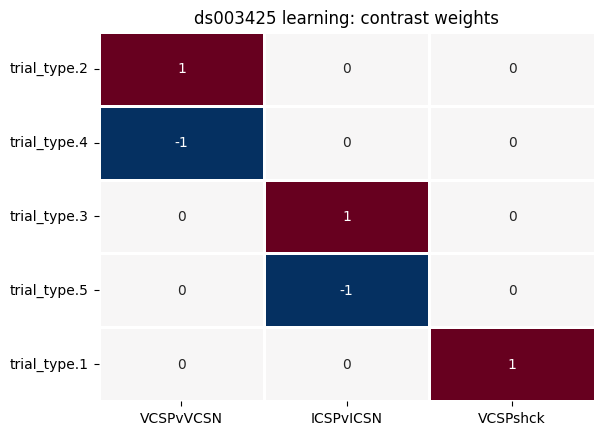

In [6]:
# The same contrasts as a weights matrix (conditions x contrasts)
W = pd.DataFrame({c["Name"]: dict(zip(c["ConditionList"], c["Weights"])) for c in contrasts["Contrasts"]}).fillna(0)
ax = sns.heatmap(W, annot=True, cmap="RdBu_r", center=0, cbar=False, linewidths=1)
ax.set_title(f"{DATASET} {TASK}: contrast weights"); plt.show()

## 4. Check the contrasts against the raw OpenNeuro events

A contrast can only work if every condition it names exists in the events. Here the subject list and one subject's
`events.tsv` come straight from the OpenNeuro bucket (`s3://openneuro.org/<dataset>/`).

In [7]:
raw_subs = nbu.list_raw_subjects(DATASET)
spec_subs = ["sub-" + s.removeprefix("sub-") for s in subjects["Subjects"]]
print(f"OpenNeuro has {len(raw_subs)} subjects; the subjects file keeps {len(spec_subs)}")
print("Excluded from the model:", sorted(set(raw_subs) - set(spec_subs)) or "none")

# find one events file for the first modelled subject
first = spec_subs[0]
_, files = nbu.s3_list(nbu.RAW_BUCKET, f"{DATASET}/{first}/", delimiter=None)
events_keys = [f["key"] for f in files if re.search(rf"task-{TASK}(_[a-z]+-\w+)*_events\.tsv$", f["key"])]
print(f"{len(events_keys)} events files for {first}; using {events_keys[0]}")
events = pd.read_csv(nbu.fetch(nbu.RAW_BUCKET, events_keys[0]), sep="\t")
events.head(8)

OpenNeuro has 13 subjects; the subjects file keeps 13
Excluded from the model: none
3 events files for sub-01; using ds003425/sub-01/ses-01/func/sub-01_ses-01_task-learning_run-01_events.tsv


,onset,duration,trial_type
0,3.544157,6.5,4
1,23.571931,6.5,1
2,43.599812,6.5,2
3,63.627571,6.5,3
4,83.655411,6.5,4
5,103.683288,6.5,3
6,123.711044,6.5,5
7,143.738938,6.5,5


In [8]:
# Conditions in the events vs. conditions the contrasts need (FitLins names them "<column>.<value>")
event_conditions = {f"trial_type.{v}" for v in events["trial_type"].unique()}
needed = {cond for c in contrasts["Contrasts"] for cond in c["ConditionList"]}
print("Conditions in this events file:", sorted(event_conditions))
print("Conditions used by contrasts:  ", sorted(needed))
print("Missing from events:", sorted(needed - event_conditions) or "none, all contrast conditions exist")

Conditions in this events file: ['trial_type.1', 'trial_type.2', 'trial_type.3', 'trial_type.4', 'trial_type.5']
Conditions used by contrasts:   ['trial_type.1', 'trial_type.2', 'trial_type.3', 'trial_type.4', 'trial_type.5']
Missing from events: none, all contrast conditions exist


## 5. The model spec (`<ds>-<task>_specs.json`)

`spec` assembles the spec from the files above. It has an `Input` block (which data to use) and a list of
`Nodes` (one per level).

In [9]:
print("Name:", spec["Name"], "| BIDSModelVersion:", spec["BIDSModelVersion"])
print("Input:", {k: (v if len(v) < 6 else f"{len(v)} values") for k, v in spec["Input"].items()})

def n_contrasts(n):
    if "Contrasts" in n:
        return len(n["Contrasts"])
    if "DummyContrasts" in n:
        return f"dummy ({n['DummyContrasts'].get('Test', '')})"
    return 0

pd.DataFrame([{
    "Level": n["Level"], "Name": n["Name"], "GroupBy": n["GroupBy"],
    "Model X": n["Model"]["X"], "Contrasts": n_contrasts(n)} for n in spec["Nodes"]])

Name: ds003425 | BIDSModelVersion: 1.0.0
Input: {'subject': '13 values', 'task': ['learning'], 'run': '6 values', 'session': ['01']}


,Level,Name,GroupBy,Model X,Contrasts
0,Run,run_level,"[run, subject, session]","[1, trial_type.*, trans_*, rot_*, cosine*]",3
1,Subject,subject_level,"[subject, contrast, session]",[1],dummy (t)
2,Dataset,data_level,"[contrast, session]",[1],dummy (t)


**How to read the nodes**
- **Run** node: builds a design matrix for each `run x subject x session` (`GroupBy`) and fits a GLM. `Model.X`
  lists the regressors: `1` is the intercept, `trial_type.*` the task conditions, then motion and drift terms.
- **Subject** node: combines each subject's runs (a fixed-effects average) *per contrast*.
- **Dataset** node: combines subjects (the group average) per contrast.

Subject and dataset nodes use `DummyContrasts` ("average this contrast"); only the run node has the real contrasts.

In [10]:
run_node = next(n for n in spec["Nodes"] if n["Level"] == "Run")
print("Run-node transformations (applied to events before the design matrix is built):")
print(json.dumps(run_node["Transformations"], indent=2))

Run-node transformations (applied to events before the design matrix is built):
{
  "Transformer": "pybids-transforms-v1",
  "Instructions": [
    {
      "Name": "Factor",
      "Input": [
        "trial_type"
      ]
    },
    {
      "Name": "Convolve",
      "Model": "spm",
      "Derivative": true,
      "Input": [
        "trial_type.*"
      ]
    }
  ]
}


`Factor` splits `trial_type` into one column per value (`trial_type.1`, `trial_type.2`, ...). `Convolve` convolves
each with the HRF (here `spm`, plus its temporal derivative).

## 6. Validate it

Before fitting, check the spec against the study files from the command line:

```bash
uv run glmfitlins validate -d <dataset> -t <task>               # subjects, runs, contrast conditions
uv run glmfitlins validate -d <dataset> -t <task> --check-design  # also builds design matrices
```

**Next:** [03_events_and_design_matrix.ipynb](03_events_and_design_matrix.ipynb)